# Task 04: Survey Data Analysis: From Raw Data to Actionable Insights


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# System utilities
import warnings
warnings.filterwarnings('ignore')

# Loading the Data

In [4]:
df = pd.read_csv(r'C:\Users\j\Desktop\Elevvo Internship Program\Tasks\Task 4 Data Cleaning and Insight Generation from Survey\data\kaggle_survey_2017_2021.csv')

# Initial Data Assessment

In [5]:
print(f"Dataset shape: {df.shape}")

Dataset shape: (106302, 293)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 106302 entries, 0 to 106301
Columns: 293 entries, - to Q38_B_OTHER
dtypes: object(293)
memory usage: 237.6+ MB


In [7]:
df.head()

,-,Time from Start to Finish (seconds),Q1,Q2,Q3,Q4,Q5,Q6,Q7_Part_1,Q7_Part_2,...,Q38_B_Part_1,Q38_B_Part_2,Q38_B_Part_3,Q38_B_Part_4,Q38_B_Part_5,Q38_B_Part_6,Q38_B_Part_7,Q38_B_Part_9,Q38_B_Part_11,Q38_B_OTHER
0,Year,Duration (in seconds),What is your age (# years)?,What is your gender? - Selected Choice,In which country do you currently reside?,What is the highest level of formal education ...,Select the title most similar to your current ...,For how many years have you been writing code ...,What programming languages do you use on a reg...,What programming languages do you use on a reg...,...,"In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor...","In the next 2 years, do you hope to become mor..."
1,2021,910,50-54,Man,India,Bachelorâ€™s degree,Other,5-10 years,Python,R,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2021,784,50-54,Man,Indonesia,Masterâ€™s degree,Program/Project Manager,20+ years,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2021,924,22-24,Man,Pakistan,Masterâ€™s degree,Software Engineer,1-3 years,Python,NaN,...,NaN,NaN,NaN,NaN,TensorBoard,NaN,NaN,NaN,NaN,NaN
4,2021,575,45-49,Man,Mexico,Doctoral degree,Research Scientist,20+ years,Python,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
print("Columns:", df.columns.tolist())


Columns: ['-', 'Time from Start to Finish (seconds)', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7_Part_1', 'Q7_Part_2', 'Q7_Part_3', 'Q7_Part_4', 'Q7_Part_5', 'Q7_Part_6', 'Q7_Part_7', 'Q7_Part_8', 'Q7_Part_9', 'Q7_Part_10', 'Q7_Part_11', 'Q7_Part_12', 'Q7_OTHER', 'Q8', 'Q9_Part_1', 'Q9_Part_2', 'Q9_Part_3', 'Q9_Part_5', 'Q9_Part_6', 'Q9_Part_7', 'Q9_Part_8', 'Q9_Part_9', 'Q9_Part_10', 'Q9_Part_12', 'Q9_OTHER', 'Q10_Part_1', 'Q10_Part_2', 'Q10_Part_3', 'Q10_Part_4', 'Q10_Part_5', 'Q10_Part_6', 'Q10_Part_7', 'Q10_Part_8', 'Q10_Part_9', 'Q10_Part_10', 'Q10_Part_11', 'Q10_Part_12', 'Q10_Part_16', 'Q10_OTHER', 'Q11', 'Q12new', 'Q12_Part_1', 'Q12_Part_2', 'Q12_Part_5', 'Q12_OTHER', 'Q13', 'Q14_Part_1', 'Q14_Part_2', 'Q14_Part_3', 'Q14_Part_4', 'Q14_Part_5', 'Q14_Part_6', 'Q14_Part_7', 'Q14_Part_8', 'Q14_Part_9', 'Q14_Part_10', 'Q14_Part_11', 'Q14_OTHER', 'Q15', 'Q16_Part_1', 'Q16_Part_2', 'Q16_Part_3', 'Q16_Part_4', 'Q16_Part_5', 'Q16_Part_6', 'Q16_Part_7', 'Q16_Part_8', 'Q16_Part_9', 'Q16_Part

# Missing Data Analysis

In [10]:
# Quick summary of missing values
missing_summary = df.isnull().sum().sort_values(ascending=False)
print("Missing values:\n", missing_summary[missing_summary > 0])

Missing values:
 Q38_B_Part_11    106301
Q34_B_Part_16    106301
Q9_Part_12       106301
Q7_Part_12       106301
Q14_Part_11      106301
                  ...  
Q5                 7214
Q4                 2983
Q1                  445
Q3                  121
Q2                   95
Length: 292, dtype: int64


In [11]:
# Separate categorical and numerical columns
categorical_cols = df.select_dtypes(include='object').columns.tolist()
numerical_cols = df.select_dtypes(include='number').columns.tolist()

print("Categorical columns:", categorical_cols[:10])  # Show first 10
print("Numerical columns:", numerical_cols)

Categorical columns: ['-', 'Time from Start to Finish (seconds)', 'Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7_Part_1', 'Q7_Part_2']
Numerical columns: []


In [12]:
# Drop columns with more than 99% missing
threshold = 0.99
df_cleaned = df.loc[:, df.isnull().mean() < threshold]
print("Remaining columns:", df_cleaned.shape[1])

Remaining columns: 212


In [13]:
# Drop exact duplicate rows
df_cleaned = df_cleaned.drop_duplicates()
print("Rows after dropping duplicates:", df_cleaned.shape[0])

Rows after dropping duplicates: 101846


In [14]:
# Clean column names: strip spaces, lowercase, replace special chars
df_cleaned.columns = (
    df_cleaned.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('[^a-z0-9_]', '', regex=True)
)

In [15]:
# Convert time column to numeric if present
if 'time_from_start_to_finish_seconds' in df_cleaned.columns:
    df_cleaned['time_from_start_to_finish_seconds'] = pd.to_numeric(
        df_cleaned['time_from_start_to_finish_seconds'], errors='coerce'
    )

In [16]:
print(df_cleaned.info())
print(df_cleaned.head())

<class 'pandas.core.frame.DataFrame'>
Index: 101846 entries, 0 to 106301
Columns: 212 entries,  to q38_b_part_9
dtypes: float64(1), object(211)
memory usage: 165.5+ MB
None
         time_from_start_to_finish_seconds                           q1  \
0  Year                                NaN  What is your age (# years)?   
1  2021                              910.0                        50-54   
2  2021                              784.0                        50-54   
3  2021                              924.0                        22-24   
4  2021                              575.0                        45-49   

                                       q2  \
0  What is your gender? - Selected Choice   
1                                     Man   
2                                     Man   
3                                     Man   
4                                     Man   

                                          q3  \
0  In which country do you currently reside?   
1        

# Insight Generation Workflow

In [17]:
# Programming Language Popularity
language_cols = [col for col in df_cleaned.columns if col.startswith('q7_part_')]

language_counts = (
    df_cleaned[language_cols]
    .apply(pd.Series.value_counts)
    .sum(axis=1)
    .sort_values(ascending=False)
)

print("Top Programming Languages:\n", language_counts.head(10))


Top Programming Languages:
 Python                   65942.0
SQL                      33090.0
R                        20884.0
Java                     14402.0
C++                      11618.0
C                         9696.0
Javascript                9501.0
MATLAB                    9320.0
Bash                      8737.0
Javascript/Typescript     3249.0
dtype: float64


In [18]:
# Country Distribution
country_counts = df_cleaned['q3'].value_counts().head(10)

print("Top Respondent Countries:\n", country_counts)


Top Respondent Countries:
 q3
India                                                   23936
United States of America                                12682
Other                                                    5532
China                                                    3502
Russia                                                   3299
Brazil                                                   3283
Japan                                                    3070
Germany                                                  2521
United States                                            2509
United Kingdom of Great Britain and Northern Ireland     2223
Name: count, dtype: int64


In [19]:
# ML Framework Usage
ml_cols = [col for col in df_cleaned.columns if col.startswith('q10_part_')]

ml_counts = (
    df_cleaned[ml_cols]
    .apply(pd.Series.value_counts)
    .sum(axis=1)
    .sort_values(ascending=False)
)

print("Top ML Frameworks:\n", ml_counts.head(10))


Top ML Frameworks:
 Colab Notebooks                 16121.0
 Kaggle Notebooks               15499.0
Kaggle Kernels                   6042.0
 Binder / JupyterHub             5523.0
JupyterHub/Binder                4916.0
 Kaggle Notebooks (Kernels)      4845.0
 Google Colab                    4551.0
Google Colab                     3532.0
Google Cloud Datalab             3101.0
 IBM Watson Studio               2582.0
dtype: float64


In [20]:
# Job Title Breakdown
job_counts = df_cleaned['q5'].value_counts().head(10)

print("Top Job Titles:\n", job_counts)


Top Job Titles:
 q5
Student                      21237
Data Scientist               16167
Software Engineer            10252
Data Analyst                  8267
Other                         8224
Research Scientist            5371
Business Analyst              4013
Currently not employed        3638
Machine Learning Engineer     3104
Data Engineer                 2466
Name: count, dtype: int64


In [21]:
# Age Distribution
age_counts = df_cleaned['q1'].value_counts().sort_index()

print("Age Distribution:\n", age_counts)


Age Distribution:
 q1
18-21                          14595
22-24                          18817
25-29                          22420
30-34                          15433
35-39                          10498
40-44                           7111
45-49                           4866
50-54                           3431
55-59                           2056
60-69                           1801
70+                              461
What is your age (# years)?        1
Name: count, dtype: int64


In [22]:
# Education Level
education_counts = df_cleaned['q4'].value_counts()

print("Education Level Distribution:\n", education_counts)


Education Level Distribution:
 q4
Masterâ€™s degree                                                                                                  37391
Bachelorâ€™s degree                                                                                                29952
Doctoral degree                                                                                                    13146
Master's degree                                                                                                     4933
Some college/university study without earning a bachelorâ€™s degree                                                 4631
Bachelor's degree                                                                                                   3474
Professional degree                                                                                                 2350
I prefer not to answer                                                                                              178

In [23]:
# IDE Usage
ide_cols = [col for col in df_cleaned.columns if col.startswith('q9_part_')]

ide_counts = (
    df_cleaned[ide_cols]
    .apply(pd.Series.value_counts)
    .sum(axis=1)
    .sort_values(ascending=False)
)

print("Top IDEs:\n", ide_counts.head(10))


Top IDEs:
 Jupyter (JupyterLab, Jupyter Notebooks, etc)     27503.0
 PyCharm                                         16791.0
Visual Studio                                    14726.0
Jupyter/IPython                                  14010.0
 RStudio                                         13052.0
  Notepad++                                      10350.0
  Spyder                                         10169.0
RStudio                                           8503.0
  Sublime Text                                    7946.0
Notepad++                                         7831.0
dtype: float64


# visualisations

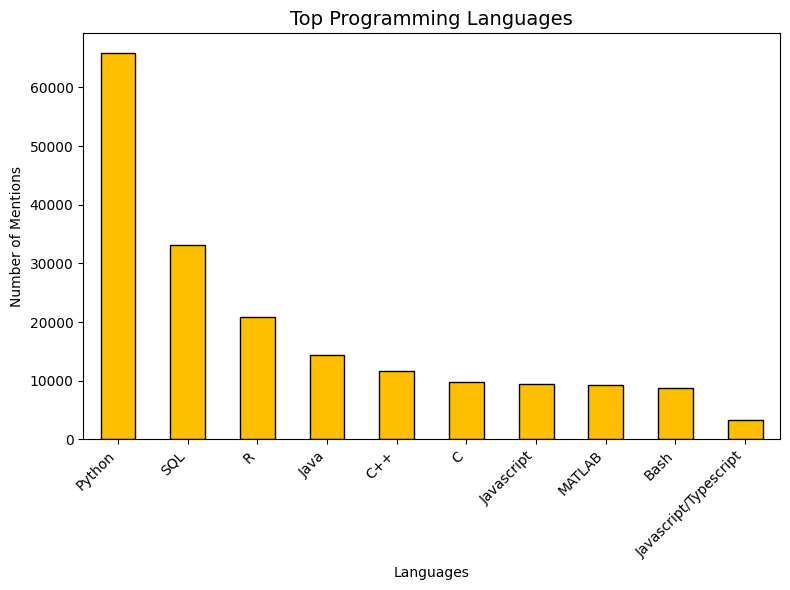

In [25]:
# Top 10 programming languages
top_languages = language_counts.head(10)

plt.figure(figsize=(8, 6))
top_languages.plot(kind='bar', color='#FFBF00', edgecolor='black')
plt.title("Top Programming Languages", fontsize=14,)
plt.ylabel("Number of Mentions")
plt.xlabel("Languages")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


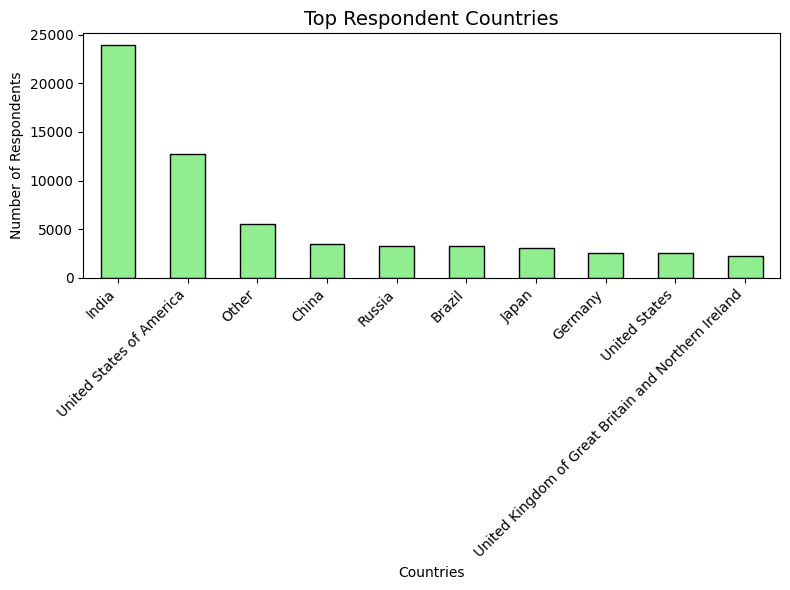

In [26]:
# Top 10 respondent countries
top_countries = country_counts

plt.figure(figsize=(8, 6))
top_countries.plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title("Top Respondent Countries", fontsize=14)
plt.ylabel("Number of Respondents")
plt.xlabel("Countries")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


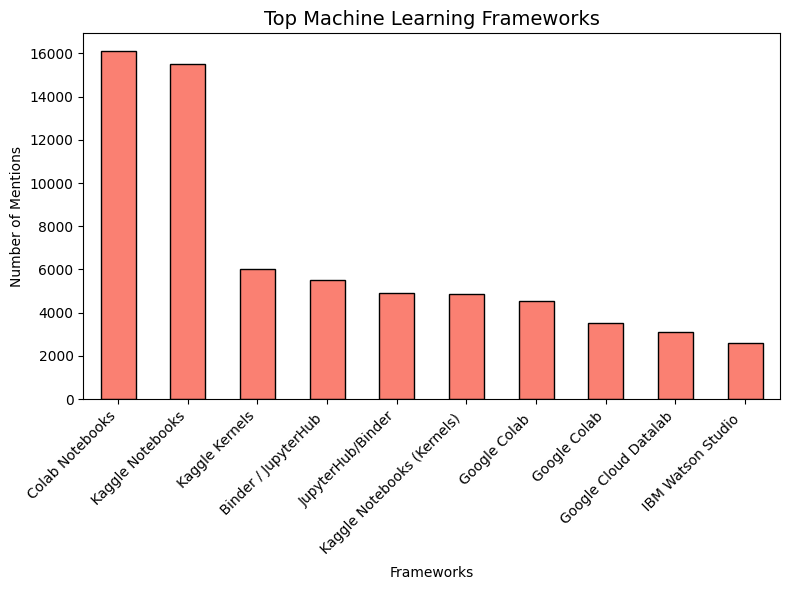

In [27]:
# Top 10 ML frameworks
top_ml = ml_counts.head(10)

plt.figure(figsize=(8, 6))
top_ml.plot(kind='bar', color='salmon', edgecolor='black')
plt.title("Top Machine Learning Frameworks", fontsize=14)
plt.ylabel("Number of Mentions")
plt.xlabel("Frameworks")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


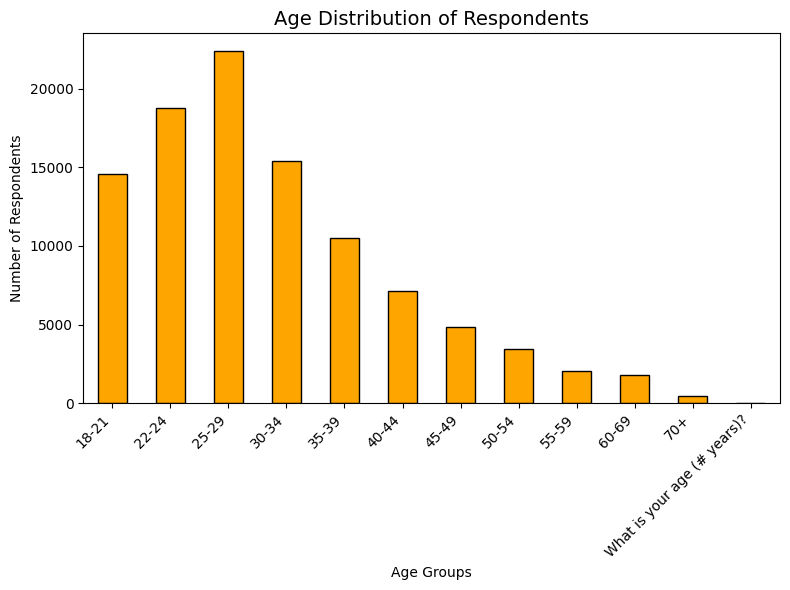

In [32]:
# Age distribution
age_dist = age_counts

plt.figure(figsize=(8, 6))
age_dist.plot(kind='bar', color='orange', edgecolor='black')
plt.title("Age Distribution of Respondents", fontsize=14)
plt.ylabel("Number of Respondents")
plt.xlabel("Age Groups")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


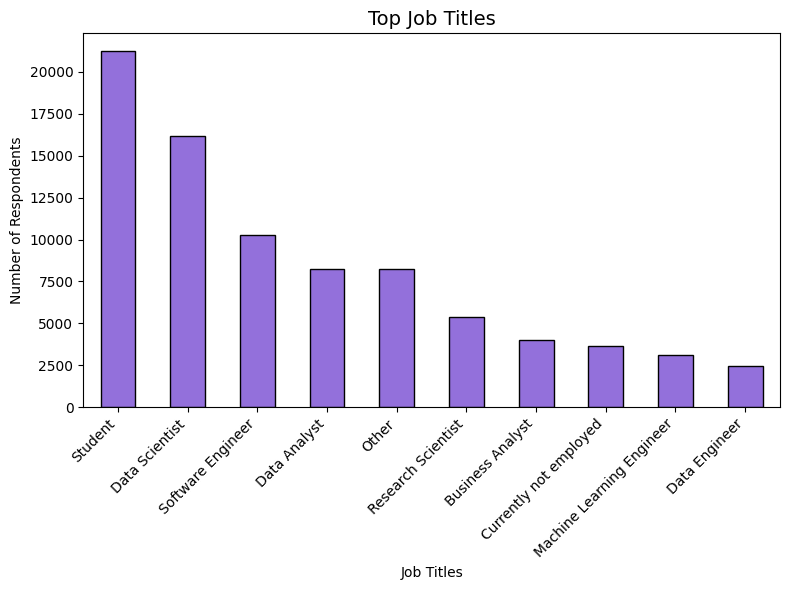

In [28]:
# Top 10 job titles
top_jobs = job_counts

plt.figure(figsize=(8, 6))
top_jobs.plot(kind='bar', color='mediumpurple', edgecolor='black')
plt.title("Top Job Titles", fontsize=14)
plt.ylabel("Number of Respondents")
plt.xlabel("Job Titles")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


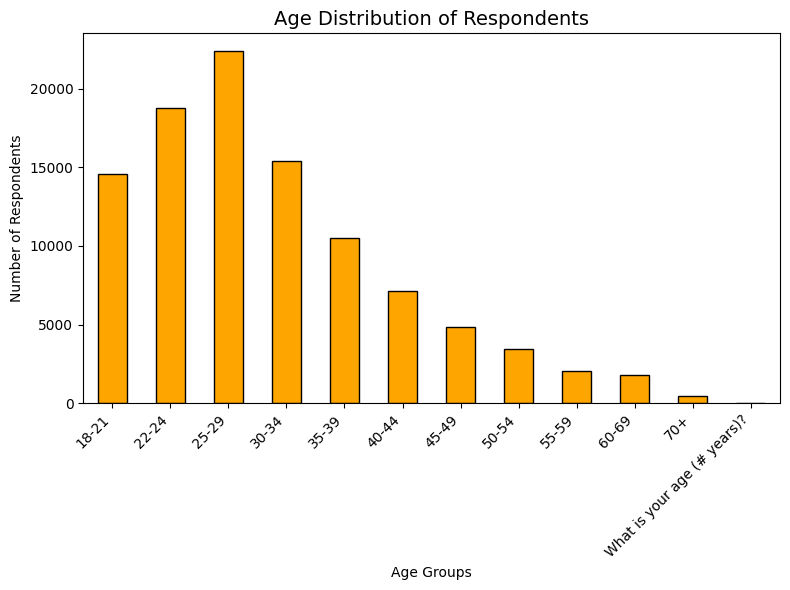

In [29]:
# Age distribution
age_dist = age_counts

plt.figure(figsize=(8, 6))
age_dist.plot(kind='bar', color='orange', edgecolor='black')
plt.title("Age Distribution of Respondents", fontsize=14)
plt.ylabel("Number of Respondents")
plt.xlabel("Age Groups")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


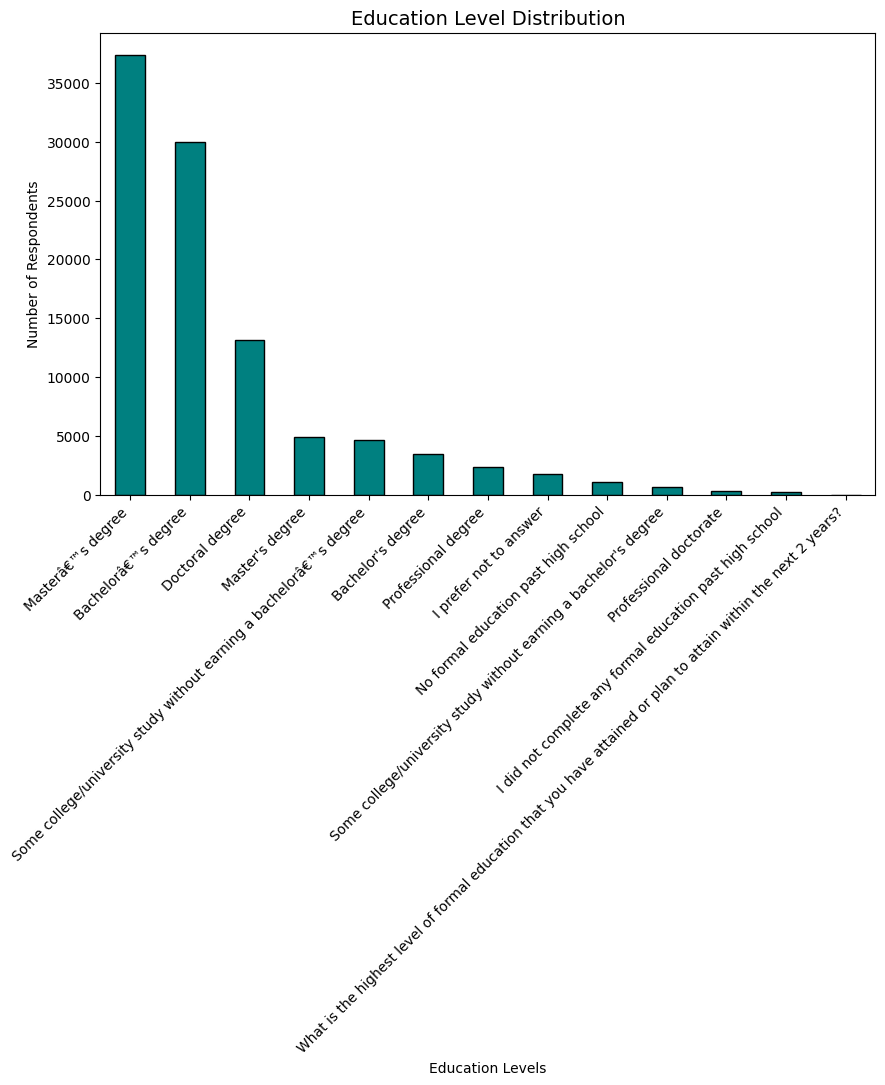

In [30]:
# Education levels
education_dist = education_counts

plt.figure(figsize=(10, 6))
education_dist.plot(kind='bar', color='teal', edgecolor='black')
plt.title("Education Level Distribution", fontsize=14)
plt.ylabel("Number of Respondents")
plt.xlabel("Education Levels")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


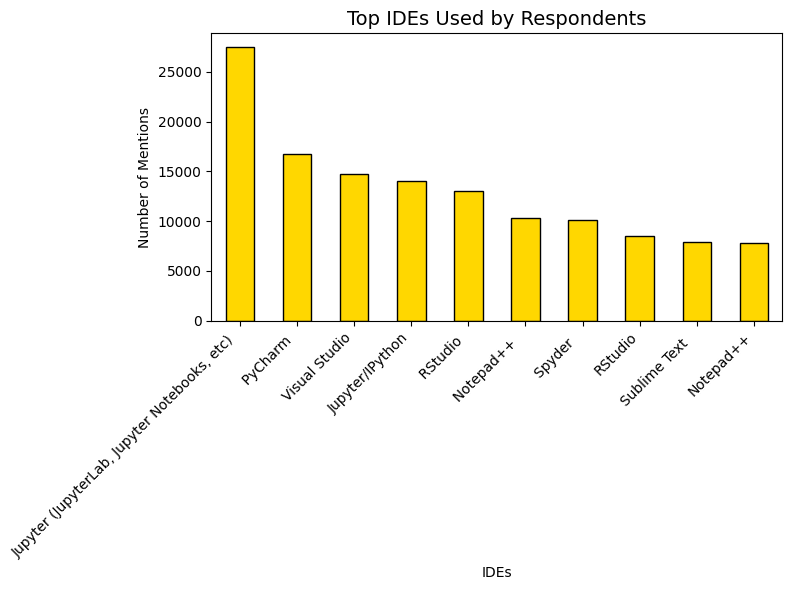

In [31]:
# Top 10 IDEs
top_ides = ide_counts.head(10)

plt.figure(figsize=(8, 6))
top_ides.plot(kind='bar', color='gold', edgecolor='black')
plt.title("Top IDEs Used by Respondents", fontsize=14)
plt.ylabel("Number of Mentions")
plt.xlabel("IDEs")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


# Interpretation

Python dominates as the primary programming language, followed by SQL and R.

Respondents are concentrated in India and the United States.

Most are students and young professionals (22–29 years old).

The majority hold a Master’s or Bachelor’s degree.

Colab and Kaggle Notebooks are the most popular ML frameworks, highlighting preference for cloud-based tools.

Jupyter Notebooks, PyCharm, and VS Code lead IDE usage.

Main roles are Data Scientist, Software Engineer, and Data Analyst.


# Summary

The data science community is young, highly educated, Python-focused, and cloud-oriented, with India and the US leading participation.